# Emotion Classifier
Using **PyTorch** & **GloVe Embeddings** to classify text emotions.

### Pipeline Overview:
* **Prep**: Clean & balance classes
* **Embedding**: Tokenize & apply pre-trained GloVe vectors
* **Model**: BiLSTM + Dense layers
* **Evaluation**: Track losses and classification metrics

## Step 1: Environment & Setup
* Install `gensim` for pre-trained vectors.
* Load core frameworks (`torch`, `pandas`, `numpy`).
* Select execution device (`cuda` or `cpu`).

In [2]:
#!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.8 MB/s  0:00:00


### Download GloVe Vectors
Loading the **100-dimensional** pre-trained Wikipedia dataset.

In [194]:
import pandas as pd
import numpy as np
import re
import torch
import torch.nn as nn
import random
import gensim.downloader as api
from collections import Counter
from torch.utils.data import Dataset,DataLoader
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
device ="cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")

Device : cuda


In [4]:
glove = api.load("glove-wiki-gigaword-100")
emb_dim = glove.vector_size

[==================================================] 100.0% 128.1/128.1MB downloaded


## Step 2: Load & Clean Data
* Import Parquet dataset.
* Remove exact duplicate records.
* View base class distribution statistics.

### Emotional State Mapping:
* **0**: Sadness | **1**: Joy | **2**: Love
* **3**: Anger | **4**: Fear | **5**: Surprise

In [5]:
#0: sadness
#1: joy
#2: love
#3: anger
#4: fear
#5: surprise

### Class Imbalance Overview
Analyzing original percentages before downsampling to prevent model bias.

In [195]:

df = pd.read_parquet('/content/train-00000-of-00001.parquet')

In [196]:
df=df.drop_duplicates()
df

,text,label
0,i feel awful about it too because it s my job ...,0
1,im alone i feel awful,0
2,ive probably mentioned this before but i reall...,1
3,i was feeling a little low few days back,0
4,i beleive that i am much more sensitive to oth...,2
...,...,...
416804,that was what i felt when i was finally accept...,1
416805,i take every day as it comes i m just focussin...,4
416806,i just suddenly feel that everything was fake,0
416807,im feeling more eager than ever to claw back w...,1


In [197]:
df.iloc[2].text

'ive probably mentioned this before but i really do feel proud of myself for actually keeping up with my new years resolution of monthly and weekly goals'

In [198]:
df.label.value_counts()

,count
label,
1,140779
0,120989
3,57235
4,47664
2,34497
5,14959


In [199]:
df.label.value_counts(normalize=True)

,proportion
label,
1,0.338311
0,0.290753
3,0.137543
4,0.114543
2,0.082901
5,0.035949


## Step 3: Class Balancing
1. **Filter**: Drop any texts mapped to multiple conflicting targets.
2. **De-duplicate**: Ensure unique texts.
3. **Cap**: Sample a maximum of **15,000 instances** per label.
4. **Shuffle**: Randomize index distribution.

### Run Balancing Process
Executing filtering and downsampling algorithms.

In [200]:
# 1. drop every copy of a text that has conflicting labels
n_labels = df.groupby("text").label.transform("nunique")
df_clean = df[n_labels == 1]

# 2. drop exact duplicates (same text, same label), keep one copy
df_clean = df_clean.drop_duplicates(subset="text")

# 3. verify
print(len(df), "->", len(df_clean))
print(df_clean.text.duplicated().sum())                      # expect 0
print(df_clean.groupby("text").label.nunique().gt(1).sum())  # expect 0
print(df_clean.label.value_counts())

416123 -> 371527
0
0
label
1    129364
0    116044
3     52327
4     39584
2     24378
5      9830
Name: count, dtype: int64


In [201]:
df=df_clean

In [202]:
for _ in range(20):
    df=df.sample(frac=1.0,random_state=42)
df=df.reset_index(drop=True)
df

,text,label
0,i feel annoyed when i am told i dont know how ...,3
1,i learn that my feelings are acceptable no mat...,1
2,i feel that connection was special and should ...,1
3,i feel will be worthwhile if only just to see ...,1
4,i feel incredibly exhausted i think i may have...,0
...,...,...
371522,i do want to be healthy although i feel strong...,1
371523,im so glad because it just left this feeling o...,1
371524,im going to wear tomorrow might not be from th...,2
371525,i cant sit here without feeling vile and disgu...,3


In [203]:
balanced_df=pd.DataFrame()
for i in range(5):
    filter=(df.label==i)
    balanced_df=pd.concat([df[filter].iloc[:15000].reset_index(drop=True),balanced_df],ignore_index=True)

balanced_df.label.value_counts()

,count
label,
4,15000
3,15000
2,15000
1,15000
0,15000


In [204]:
filter=(df.label==5)
balanced_df=pd.concat([df[filter].reset_index(drop=True),balanced_df],ignore_index=True)
balanced_df.label.value_counts()

,count
label,
4,15000
3,15000
1,15000
2,15000
0,15000
5,9830


In [205]:
for _ in range(20):
    balanced_df=balanced_df.sample(frac=1.0,random_state=42)

In [206]:
balanced_df=balanced_df.reset_index(drop=True)


## Step 4: Tokenization & Word Encoding
* Parse words & capture punctuation markers.
* Build custom vocabulary with special `<pad>` and `<unk>` tokens.
* Map matching words to GloVe embeddings.

### Vocab Embedding Diagnostics
Checking embedding matrix dimensions and tracking Out-of-Vocabulary (OOV) tokens.

In [207]:
texts=balanced_df.text.tolist()
labels=balanced_df.label.tolist()

In [208]:
def tokenize(text):
    return re.findall(r"\w+|[?!]", text.lower())
tokenized=[ tokenize(text) for text in texts ]
counter=Counter(word for t in tokenized for word in t)
vocab={}
index_to_vocab={}
pad="<pad>"
unk="<unk>"
vocab[pad]=len(vocab)
vocab[unk]=len(vocab)
for word in counter.keys():
    vocab[word]=len(vocab)
index_to_vocab = {i: w for w, i in vocab.items()}
maxlen=max(len (t) for  t in tokenized )
maxlen
def encode(t,maxlen):
    ids=[vocab.get(word,vocab[unk])for word in t ]
    ids=ids+(maxlen-len(ids))*[vocab[pad]]
    return ids
X=torch.tensor([encode(t,maxlen)for t in tokenized])
matrix=np.random.normal(size=(len(vocab),emb_dim),scale=1.0)
matrix[vocab[pad]]=0
Found=0
not_Found=0
for word,id in vocab.items():
    if word in glove:
        matrix[id]=glove[word]
        Found+=1
    else :
        not_Found+=1
print(f"Found Words : {Found},Not Found words : {not_Found} ")

matrix=torch.tensor(matrix,dtype=torch.float32)
emb=torch.nn.Embedding.from_pretrained(matrix,freeze=True,padding_idx=vocab[pad])
print(f"embedding shape : {emb(X).shape}")

Found Words : 31213,Not Found words : 5037 
embedding shape : torch.Size([84830, 110, 100])


## Step 5: Split Data & Loaders
* Split dataset into **80% Train / 10% Dev / 10% Test** splits.
* Construct PyTorch `Dataset` wrapper.
* Instantiate batch loaders (`batch_size=128`).

### Dataset & DataLoader Setup
Instantiating batch generators with enabled shuffling for training stability.

In [209]:
Y=torch.tensor(labels,dtype=torch.long)
Y.shape

torch.Size([84830])

In [210]:
train_size=int(0.8*len(X))
dev_size=int(0.1*len(X))
test_size=int(0.1*len(X))
train_size,dev_size,test_size

(67864, 8483, 8483)

In [211]:
X_train,Y_train=X[:train_size],Y[:train_size]
X_dev,Y_dev=X[train_size:train_size+dev_size],Y[train_size:train_size+dev_size]
X_test,Y_test=X[train_size+dev_size:],Y[train_size+dev_size:]
X_test.shape,Y_test.shape,X_dev.shape,Y_dev.shape,X_train.shape,Y_train.shape,


(torch.Size([8483, 110]),
 torch.Size([8483]),
 torch.Size([8483, 110]),
 torch.Size([8483]),
 torch.Size([67864, 110]),
 torch.Size([67864]))

In [212]:
class MyData(Dataset):
    def __init__(self,X,Y):
        self.X=X
        self.Y=Y
    def __len__(self):
        return len(self.X)

    def __getitem__(self,idx):
        return self.X[idx],self.Y[idx]


In [213]:
train_data=MyData(X_train,Y_train)
dev_data=MyData(X_dev,Y_dev)
test_data=MyData(X_test,Y_test)
train_loader=DataLoader(train_data,shuffle=True,batch_size=128)
dev_loader=DataLoader(dev_data,shuffle=True,batch_size=128)
test_loader=DataLoader(test_data,shuffle=True,batch_size=128)

## Step 6: Neural Network Architecture
* **Embedding Layer**: Frozen pre-trained embeddings.
* **BiLSTM Layer**: 2 bidirectional recurrent layers capture forward & backward context.
* **Classification Head**: Dense feedforward layers with Dropout and ReLU activations.

### Initialize Network & Training Configuration
* Instantiate model topology
* Set **Cross Entropy Loss** criteria
* Define **Adam Optimizer** with `lr=0.001`

In [214]:
next(iter(train_loader))

[tensor([[  2,  15,  13,  ...,   0,   0,   0],
         [  2, 242,  15,  ...,   0,   0,   0],
         [  2,  48, 103,  ...,   0,   0,   0],
         ...,
         [  2, 256,  24,  ...,   0,   0,   0],
         [  2,  15,  44,  ...,   0,   0,   0],
         [  2,  15,  58,  ...,   0,   0,   0]]),
 tensor([1, 4, 1, 1, 0, 2, 1, 2, 1, 2, 2, 4, 0, 0, 4, 5, 2, 2, 0, 4, 5, 5, 0, 1,
         3, 5, 0, 0, 2, 5, 5, 1, 1, 5, 3, 2, 4, 0, 0, 5, 4, 0, 1, 4, 4, 0, 3, 3,
         5, 4, 1, 3, 3, 0, 2, 2, 1, 0, 3, 3, 0, 4, 3, 1, 3, 4, 2, 1, 2, 1, 5, 0,
         0, 2, 4, 0, 5, 4, 3, 5, 4, 2, 2, 3, 0, 3, 2, 3, 2, 1, 5, 0, 1, 4, 1, 5,
         4, 4, 3, 0, 0, 1, 4, 4, 0, 1, 4, 3, 4, 2, 0, 4, 0, 0, 5, 0, 2, 3, 1, 2,
         5, 2, 1, 3, 2, 3, 3, 2])]

In [215]:
from torch.nn.utils.rnn import pack_padded_sequence
class Model(nn.Module):
    def __init__(self, emb, hidden=256, out_classes=6, lstm_dropout=0.2, head_dropout=0.4):
        super().__init__()
        self.emb = emb
        self.lstm = nn.LSTM(
            input_size=emb.embedding_dim,
            hidden_size=hidden,
            num_layers=2,
            bidirectional=True,
            dropout=lstm_dropout,
            batch_first=True
        )
        self.FC1 = nn.Linear(hidden * 2, 256)
        self.FC2 = nn.Linear(256, 128)
        self.FC3 = nn.Linear(128, 64)
        self.FC4 = nn.Linear(64, out_classes)
        self.act = nn.ReLU()
        self.dropout = nn.Dropout(head_dropout)
        self.init_weights()

    def init_weights(self):
        for name, p in self.lstm.named_parameters():
            if "weight_ih" in name:
                nn.init.xavier_uniform_(p)
            elif "weight_hh" in name:
                nn.init.orthogonal_(p)
            elif "bias" in name:
                nn.init.zeros_(p)
                n = p.size(0)
                p.data[n // 4: n // 2].fill_(1.0)
        for layer in (self.FC1, self.FC2, self.FC3):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
        nn.init.xavier_uniform_(self.FC4.weight)
        nn.init.zeros_(self.FC4.bias)

    def head(self, h):
        h = self.dropout(self.act(self.FC1(h)))
        h = self.dropout(self.act(self.FC2(h)))
        h = self.dropout(self.act(self.FC3(h)))
        return self.FC4(h)

    def forward(self, X):
        lengths = (X != 0).sum(dim=1).clamp(min=1)
        X = self.emb(X)
        packed = pack_padded_sequence(X, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat((h[-2], h[-1]), dim=1)
        return self.head(h)

In [216]:
model=Model(emb)
criterion=nn.CrossEntropyLoss()


In [217]:
optim=torch.optim.Adam(model.parameters(),lr=0.001)

In [218]:
@torch.no_grad()
def Calculate_Loss(model,criterion,loader):
    model.eval()
    total_loss=0
    n=0
    for X,Y in loader:
        X=X.to(device)
        Y=Y.to(device)
        logits=model(X)
        Loss=criterion(logits,Y)
        total_loss+=Loss.item()
        n+=1
    return total_loss/n



In [219]:
def Train(model,criterion,optim,n_epochs,train_loader,dev_loader):
    model.to(device)
    Train_Losses=[]
    Dev_Losses=[]
    for epoch in range(n_epochs):
        model.train(True)
        total_train_loss=0
        n=0
        for i, (X,Y) in enumerate(train_loader):
            optim.zero_grad()
            X=X.to(device)
            Y=Y.to(device)
            logits=model(X)
            Loss=criterion(logits,Y)
            Loss.backward()
            optim.step()
            total_train_loss+=Loss.item()
            n+=1
        model.eval()
        dev_loss=Calculate_Loss(model,criterion,dev_loader)
        Train_Losses.append(total_train_loss/n)
        Dev_Losses.append(dev_loss)
        print(f"Epoch {epoch+1} : Train Loss ={Train_Losses[-1]:.3f} Dev Loss ={Dev_Losses[-1]:.3f}")
    return Train_Losses,Dev_Losses









## Step 7: Train Network
* Execute train loops across **20 epochs**.
* Compute average validation losses periodically to trace convergence.

### Train & Dev Loss Trajectory
Visualizing loss decay metrics over training cycles to verify optimization.

In [221]:

train_losses,dev_losses=Train(model,criterion,optim,20,train_loader,dev_loader)

Epoch 1 : Train Loss =1.691 Dev Loss =1.339
Epoch 2 : Train Loss =1.147 Dev Loss =0.766
Epoch 3 : Train Loss =0.525 Dev Loss =0.153
Epoch 4 : Train Loss =0.146 Dev Loss =0.092
Epoch 5 : Train Loss =0.085 Dev Loss =0.104
Epoch 6 : Train Loss =0.063 Dev Loss =0.070
Epoch 7 : Train Loss =0.050 Dev Loss =0.062
Epoch 8 : Train Loss =0.040 Dev Loss =0.058
Epoch 9 : Train Loss =0.033 Dev Loss =0.068
Epoch 10 : Train Loss =0.034 Dev Loss =0.059


## Step 8: Evaluate Performance
* Compute multi-class **F1-Score, Precision, and Recall** rates.
* Generate **Confusion Matrices** to observe misclassifications.

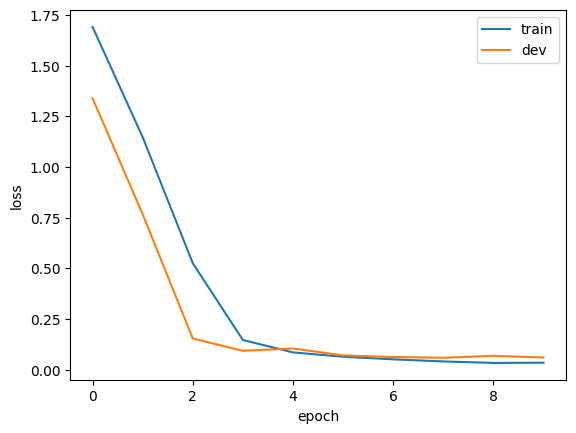

In [222]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="train")
plt.plot(dev_losses, label="dev")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## Step 9: Real-Time Sentence Inference
An interactive tool to run predictions on single sentence strings.

### Test Sample Output
Predicting emotional labels on a custom input phrase.

In [223]:
Calculate_Loss(model,criterion,test_loader)

0.05887722098524856

In [224]:
from sklearn.metrics import classification_report

@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    for X, Y in loader:
        X = X.to(device)
        logits = model(X)
        preds = logits.argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(Y.tolist())
    return all_labels, all_preds



In [225]:
y_train_true, y_train_pred = get_predictions(model, train_loader)
print(classification_report(y_train_true, y_train_pred, digits=3))

              precision    recall  f1-score   support

           0      0.998     0.987     0.993     12005
           1      0.997     0.993     0.995     12017
           2      0.999     1.000     0.999     11966
           3      0.979     0.996     0.988     12000
           4      0.994     0.985     0.990     11984
           5      0.989     1.000     0.994      7892

    accuracy                          0.993     67864
   macro avg      0.993     0.993     0.993     67864
weighted avg      0.993     0.993     0.993     67864



In [226]:
y_dev_true, y_dev_pred = get_predictions(model, dev_loader)
print(classification_report(y_dev_true, y_dev_pred, digits=3))

              precision    recall  f1-score   support

           0      0.993     0.971     0.982      1509
           1      0.990     0.983     0.986      1500
           2      0.997     0.995     0.996      1546
           3      0.964     0.990     0.977      1484
           4      0.984     0.978     0.981      1471
           5      0.981     0.998     0.989       973

    accuracy                          0.985      8483
   macro avg      0.985     0.986     0.985      8483
weighted avg      0.985     0.985     0.985      8483



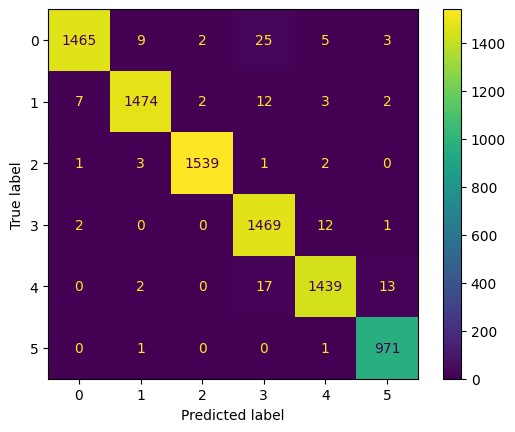

In [227]:
from sklearn.metrics import ConfusionMatrixDisplay
print(ConfusionMatrixDisplay.from_predictions(y_dev_true, y_dev_pred))

In [228]:
y_test_true, y_test_pred = get_predictions(model, test_loader)
print(classification_report(y_test_true, y_test_pred, digits=3))

              precision    recall  f1-score   support

           0      0.991     0.976     0.983      1486
           1      0.989     0.981     0.985      1483
           2      0.993     0.994     0.994      1488
           3      0.970     0.990     0.980      1516
           4      0.986     0.981     0.984      1545
           5      0.987     0.998     0.992       965

    accuracy                          0.986      8483
   macro avg      0.986     0.987     0.986      8483
weighted avg      0.986     0.986     0.986      8483



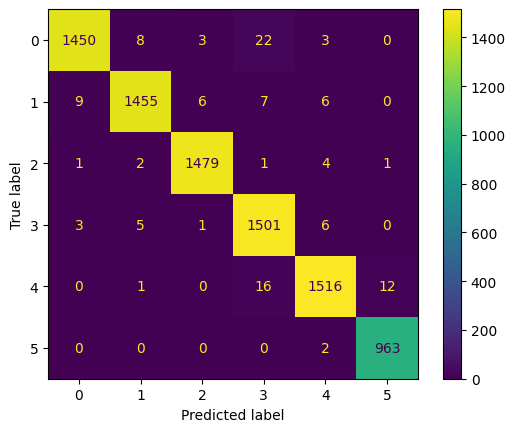

In [229]:
print(ConfusionMatrixDisplay.from_predictions(y_test_true, y_test_pred))

## 9. Interactive Sentence Inference
An interactive function to test your own custom sentences and output predicted emotion probabilities.

### Interactive Inference

Finally, we define a helper function to run real-time inference on arbitrary new sentences to classify their sentiment and examine predicted confidence scores.

In [230]:

id2label = {0: "sadness", 1: "joy", 2: "love", 3: "anger", 4: "fear", 5: "surprise"}

@torch.no_grad()
def predict(sentence, model):
    model.eval()
    tokens = tokenize(sentence)[:maxlen]
    ids = [vocab.get(w, vocab[unk]) for w in tokens]
    if len(ids) == 0:
        ids = [vocab[unk]]
    x = torch.tensor([ids], dtype=torch.long).to(device)

    probs = torch.softmax(model(x), dim=1).squeeze(0).cpu()
    pred_id = probs.argmax().item()

    return {
        "sentence": sentence,
        "prediction": id2label[pred_id],
        "confidence": probs[pred_id].item(),
        "probabilities": {id2label[i]: probs[i].item() for i in range(len(probs))},
    }

In [242]:
result = predict("i just got the job offer i applied for last month", model)

print(f"Sentence   : {result['sentence']}")
print(f"Prediction : {result['prediction']} ({result['confidence']:.1%})")
print("All probabilities:")
for label, p in sorted(result["probabilities"].items(), key=lambda kv: -kv[1]):
    print(f"   {label:9s} {p:.1%}")

Sentence   : i just got the job offer i applied for last month
Prediction : joy (83.7%)
All probabilities:
   joy       83.7%
   anger     6.2%
   sadness   5.4%
   fear      3.6%
   love      0.8%
   surprise  0.4%
